# _tobac_ example: tracking DCCs in ISCCP-NG data during the ORCESTRA campaign

In this example, we will explore tracking of deep convection in ISCCP-NG merged geostationary satellite data during the ORCESTRA campaign period using overlap tracking techniques.
  1. Accessing geo-ring data remotely, visualisation
  2. Conversion of healpix grid data to a regular lat/lon grid for tracking
  3. Feature detection, segmentation and overlap tracking on merged satellite IR observations
  4. Colocation with HALO aircraft observations (?)


In [1]:

import s3fs
import xarray as xr

s3 = s3fs.S3FileSystem(
    anon=True,
    client_kwargs={"endpoint_url": "https://s3.waw3-1.cloudferro.com/"},
)

store = s3.get_mapper("level1g/zarr")

ds = xr.open_zarr(
    store,
    chunks=None,
    consolidated=True,
    zarr_format=3,
    drop_variables=["slot_metadata"],
)

In [2]:
ds

<xarray.Dataset> Size: 11PB
Dimensions:                  (time: 1402560, layer: 3, healpix_index: 12582912)
Coordinates:
  * time                     (time) datetime64[ns] 11MB 1970-01-01 ... 2049-1...
  * healpix_index            (healpix_index) int32 50MB 0 1 ... 12582911
Dimensions without coordinates: layer
Data variables: (12/27)
    pixel_time               (time, layer, healpix_index) datetime64[ns] 424TB ...
    refl_00_47um             (time, layer, healpix_index) float64 424TB ...
    refl_00_51um             (time, layer, healpix_index) float64 424TB ...
    refl_00_65um             (time, layer, healpix_index) float64 424TB ...
    refl_00_65um_resolution  (time, layer, healpix_index) float64 424TB ...
    refl_00_65um_std         (time, layer, healpix_index) float64 424TB ...
    ...                       ...
    temp_10_40um             (time, layer, healpix_index) float64 424TB ...
    temp_11_00um             (time, layer, healpix_index) float64 424TB ...
    temp_11_00um_resolution  (time, layer, healpix_index) float64 424TB ...
    temp_11_00um_std         (time, layer, healpix_index) float64 424TB ...
    temp_12_00um             (time, layer, healpix_index) float64 424TB ...
    temp_13_30um             (time, layer, healpix_index) float64 424TB ...
Attributes:
    zarr_conventions:  [{'schema_url': 'https://raw.githubusercontent.com/zar...
    dggs:              {'name': 'healpix', 'refinement_level': 10, 'indexing_...

In [3]:
# Let's select the 3rd September 'golden case'
ds = ds.sel(time=slice("2024-08-27-00:00:00", "2024-08-28-00:00:00")).isel(layer=0)[["temp_06_20um", "temp_07_30um", "temp_11_00um"]]

In [4]:
ds

<xarray.Dataset> Size: 15GB
Dimensions:        (time: 49, healpix_index: 12582912)
Coordinates:
  * time           (time) datetime64[ns] 392B 2024-08-27 ... 2024-08-28
  * healpix_index  (healpix_index) int32 50MB 0 1 2 ... 12582910 12582911
Data variables:
    temp_06_20um   (time, healpix_index) float64 5GB ...
    temp_07_30um   (time, healpix_index) float64 5GB ...
    temp_11_00um   (time, healpix_index) float64 5GB ...
Attributes:
    zarr_conventions:  [{'schema_url': 'https://raw.githubusercontent.com/zar...
    dggs:              {'name': 'healpix', 'refinement_level': 10, 'indexing_...

In [5]:
import numpy as np
import healpix

axis_extent = [-64, -4, -8, 24]

lon = xr.DataArray(
    np.arange(axis_extent[0]+0.025, axis_extent[2], 0.05),
    dims=("lon",), 
    name="lon", 
    attrs=dict(units="degrees", standard_name="longitude")
)

lat = xr.DataArray(
    np.arange(axis_extent[1]+0.025, axis_extent[3], 0.05), 
    dims=("lat",), 
    name="lat", 
    attrs=dict(units="degrees", standard_name="latitude")
)

pix = xr.DataArray(
    healpix.ang2pix(2**ds.dggs["refinement_level"], *np.meshgrid(lon, lat), nest=ds.dggs["indexing_scheme"], lonlat=True),
    coords=(lat, lon),
)

In [6]:
ds_gridded = ds[["temp_06_20um", "temp_07_30um", "temp_11_00um"]].isel(healpix_index=pix)

In [7]:
wvd = ds_gridded.temp_06_20um.compute() - ds_gridded.temp_07_30um.compute()

Text(0.0, 1.0, 'WVD')

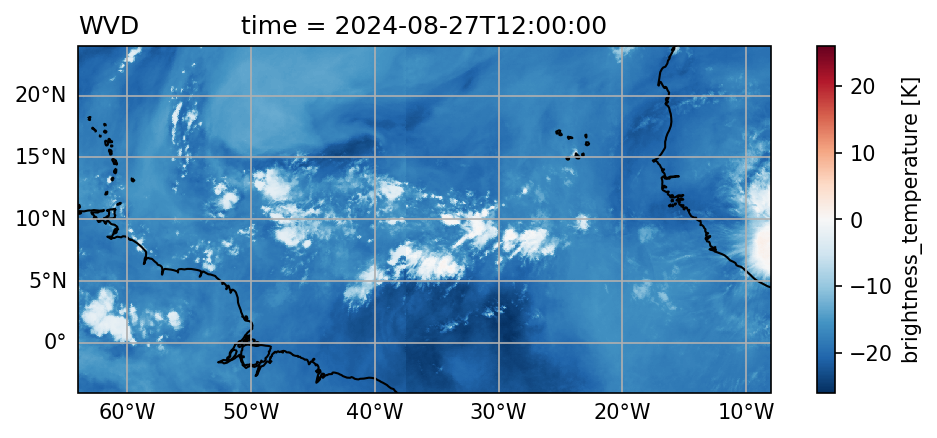

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
fig, ax = plt.subplots(dpi=150, subplot_kw={"projection":ccrs.PlateCarree()}, figsize=(8,3))
ax.coastlines()
ax.gridlines(draw_labels=["left", "bottom"], x_inline=False, y_inline=False)
wvd.isel(time=24).plot(ax=ax)
ax.set_title("WVD", loc="left")

In [9]:
import tobac

In [10]:
labels, features = tobac.feature_detection_multithreshold(
    wvd, dxy=5.55e3, threshold=[-12.5,-10,-7.5,-5], n_min_threshold=1, target="maximum", return_labels=True, position_threshold="extreme"
)

In [11]:
features

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,healpix_index,lat,lon
0,0,3,0,193,5,-12.5,1,2024-08-27,2024-08-27 00:00:00,7675424.0,-3.975,-54.325
1,0,4,6,287,8,-12.5,2,2024-08-27,2024-08-27 00:00:00,7684430.0,-3.675,-49.625
2,0,5,14,40,41,-12.5,3,2024-08-27,2024-08-27 00:00:00,7701286.0,-3.275,-61.975
3,0,6,21,23,17,-12.5,4,2024-08-27,2024-08-27 00:00:00,7702622.0,-2.925,-62.825
4,0,8,22,12,2,-12.5,5,2024-08-27,2024-08-27 00:00:00,7702728.0,-2.875,-63.375
...,...,...,...,...,...,...,...,...,...,...,...,...
19907,48,769,505,973,28,-5.0,19908,2024-08-28,2024-08-28 00:00:00,5157986.0,21.275,-15.325
19908,48,770,521,114,39,-5.0,19909,2024-08-28,2024-08-28 00:00:00,3328619.0,22.075,-58.275
19909,48,771,526,1008,2,-5.0,19910,2024-08-28,2024-08-28 00:00:00,5163753.0,22.325,-13.575
19910,48,772,529,115,33,-5.0,19911,2024-08-28,2024-08-28 00:00:00,3328757.0,22.475,-58.225


Text(0.0, 1.0, 'Features')

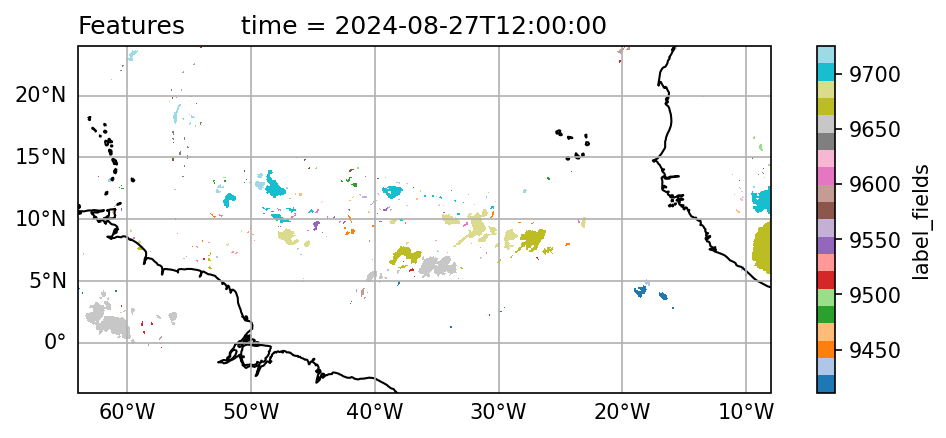

In [12]:
fig, ax = plt.subplots(dpi=150, subplot_kw={"projection":ccrs.PlateCarree()}, figsize=(8,3))
ax.coastlines()
ax.gridlines(draw_labels=["left", "bottom"], x_inline=False, y_inline=False)
labels.where(labels>0).isel(time=24).plot(ax=ax, cmap="tab20")
ax.set_title("Features", loc="left")

In [13]:
segmentation_mask, features = tobac.segmentation_2D(
    features, wvd, dxy=5.55e3, threshold=-12.5, target="maximum",
)

features = features[np.isin(features.feature, segmentation_mask)]

Text(0.0, 1.0, 'Segments')

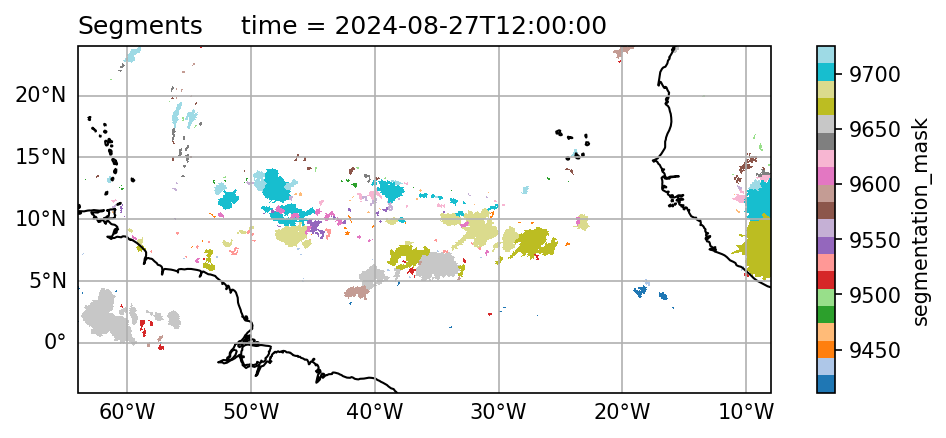

In [14]:
fig, ax = plt.subplots(dpi=150, subplot_kw={"projection":ccrs.PlateCarree()}, figsize=(8,3))
ax.coastlines()
ax.gridlines(draw_labels=["left", "bottom"], x_inline=False, y_inline=False)
segmentation_mask.where(segmentation_mask>0).isel(time=24).plot(ax=ax, cmap="tab20")
ax.set_title("Segments", loc="left")

In [15]:
from tobac.tracking import linking_overlap

In [16]:
tracks = linking_overlap(
    features, segmentation_mask, stubs=3, minimum_relative_overlap=0.5, translate_method="predict", PBC_flag="none"
)

In [17]:
tracks

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,healpix_index,lat,lon,ncells,cell,time_cell
0,0,3,0,193,5,-12.5,1,2024-08-27,2024-08-27 00:00:00,7675424.0,-3.975,-54.325,6,-1,NaT
1,0,4,6,287,8,-12.5,2,2024-08-27,2024-08-27 00:00:00,7684430.0,-3.675,-49.625,11,-1,NaT
2,0,5,14,40,41,-12.5,3,2024-08-27,2024-08-27 00:00:00,7701286.0,-3.275,-61.975,41,-1,NaT
3,0,6,21,23,17,-12.5,4,2024-08-27,2024-08-27 00:00:00,7702622.0,-2.925,-62.825,13,-1,NaT
4,0,8,22,12,2,-12.5,5,2024-08-27,2024-08-27 00:00:00,7702728.0,-2.875,-63.375,3,-1,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19907,48,769,505,973,28,-5.0,19908,2024-08-28,2024-08-28 00:00:00,5157986.0,21.275,-15.325,130,-1,NaT
19908,48,770,521,114,39,-5.0,19909,2024-08-28,2024-08-28 00:00:00,3328619.0,22.075,-58.275,123,1486,0 days 04:30:00
19909,48,771,526,1008,2,-5.0,19910,2024-08-28,2024-08-28 00:00:00,5163753.0,22.325,-13.575,60,-1,NaT
19910,48,772,529,115,33,-5.0,19911,2024-08-28,2024-08-28 00:00:00,3328757.0,22.475,-58.225,89,1751,0 days 01:00:00


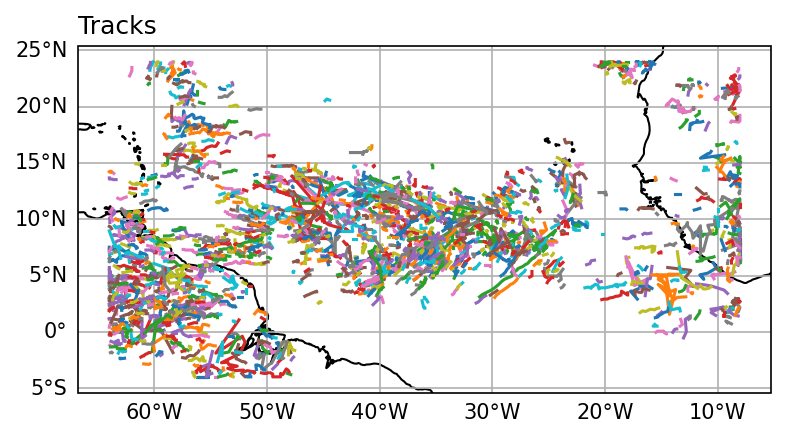

In [18]:
fig, ax = plt.subplots(dpi=150, subplot_kw={"projection":ccrs.PlateCarree()}, figsize=(8,3))
ax.coastlines()
ax.gridlines(draw_labels=["left", "bottom"], x_inline=False, y_inline=False)
lines = tracks[tracks.cell!=-1].groupby("cell").plot(ax=ax, x="lon", y="lat", legend=False)
ax.set_title("Tracks", loc="left")
_ = ax.set_yticks([])

In [19]:
import pandas as pd
import shapely
from shapely import GEOSException
import geopandas as gpd
from skimage.measure import find_contours, regionprops

def get_geometry_for_contour(regionprops_obj):
    coords = [
        (p + np.array(regionprops_obj.bbox[:2])) 
        for p in find_contours(np.pad(regionprops_obj.image, 1), fully_connected="low")
    ]
    try:
        return shapely.MultiPolygon(
            [
                shapely.Polygon(
                    np.stack([0.05*c[:,1]-63.975, 0.05*c[:,0]-7.975], axis=-1) #TODO interpolate coordinates rather than hardcoded
                )
                for c in coords
            ]
        )
    except GEOSException:
        return None

def get_gpd_for_anvil_labels(labels: xr.DataArray, timestep=pd.Timestamp) -> gpd.GeoDataFrame:
    # valid_labels = labels.where(np.isin(labels, valid_anvils), 0)
    # rps = regionprops(valid_labels.values)
    rps = regionprops(labels.values)
    geoms = [
        get_geometry_for_contour(r)
        for r in rps
    ]
    labels = [int(r.label) for r in rps]
    return gpd.GeoDataFrame(data=dict(anvil=labels, time=timestep), geometry=geoms, crs="EPSG:4326")


In [20]:
tracks_gpd = gpd.GeoDataFrame(
    tracks,
    geometry=pd.concat(
        [
            get_gpd_for_anvil_labels(segmentation_mask.isel(time=i), timestep=timestep) 
            for i, timestep in enumerate(segmentation_mask.time.values)
        ],
        ignore_index=True
    ).geometry
)

In [21]:
tracks_gpd

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,healpix_index,lat,lon,ncells,cell,time_cell,geometry
0,0,3,0,193,5,-12.5,1,2024-08-27,2024-08-27 00:00:00,7675424.0,-3.975,-54.325,6,-1,NaT,"MULTIPOLYGON (((-54.225 -7.85, -54.25 -7.875, ..."
1,0,4,6,287,8,-12.5,2,2024-08-27,2024-08-27 00:00:00,7684430.0,-3.675,-49.625,11,-1,NaT,"MULTIPOLYGON (((-49.575 -7.55, -49.625 -7.55, ..."
2,0,5,14,40,41,-12.5,3,2024-08-27,2024-08-27 00:00:00,7701286.0,-3.275,-61.975,41,-1,NaT,"MULTIPOLYGON (((-61.525 -7.1, -61.575 -7.1, -6..."
3,0,6,21,23,17,-12.5,4,2024-08-27,2024-08-27 00:00:00,7702622.0,-2.925,-62.825,13,-1,NaT,"MULTIPOLYGON (((-62.675 -6.6, -62.7 -6.625, -6..."
4,0,8,22,12,2,-12.5,5,2024-08-27,2024-08-27 00:00:00,7702728.0,-2.875,-63.375,3,-1,NaT,"MULTIPOLYGON (((-63.275 -6.8, -63.325 -6.8, -6..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19907,48,769,505,973,28,-5.0,19908,2024-08-28,2024-08-28 00:00:00,5157986.0,21.275,-15.325,130,-1,NaT,"MULTIPOLYGON (((-15.025 17.65, -15.05 17.625, ..."
19908,48,770,521,114,39,-5.0,19909,2024-08-28,2024-08-28 00:00:00,3328619.0,22.075,-58.275,123,1486,0 days 04:30:00,"MULTIPOLYGON (((-57.975 18.4, -58 18.375, -58...."
19909,48,771,526,1008,2,-5.0,19910,2024-08-28,2024-08-28 00:00:00,5163753.0,22.325,-13.575,60,-1,NaT,"MULTIPOLYGON (((-13.225 18.65, -13.25 18.625, ..."
19910,48,772,529,115,33,-5.0,19911,2024-08-28,2024-08-28 00:00:00,3328757.0,22.475,-58.225,89,1751,0 days 01:00:00,"MULTIPOLYGON (((-57.825 18.85, -57.85 18.825, ..."


Text(0.0, 1.0, 'Geometry')

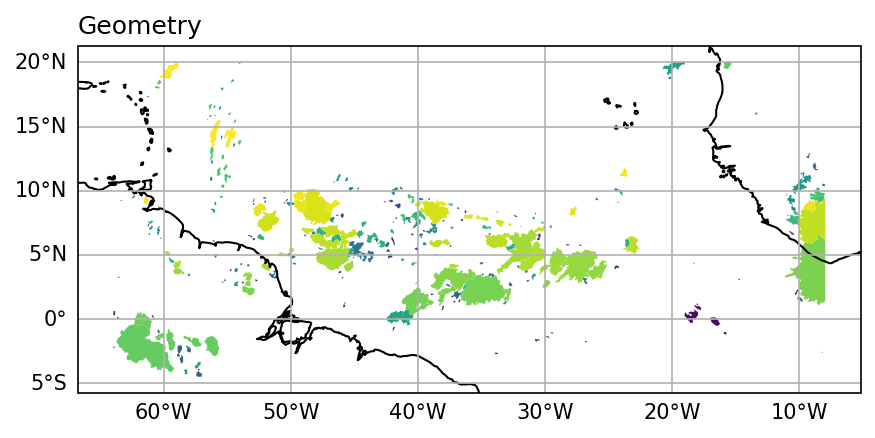

In [22]:
fig, ax = plt.subplots(dpi=150, subplot_kw={"projection":ccrs.PlateCarree()}, figsize=(8,3))
ax.coastlines()
ax.gridlines(draw_labels=["left", "bottom"], x_inline=False, y_inline=False)
tracks_gpd[tracks_gpd.frame==24].plot("feature", ax=ax)
ax.set_title("Geometry", loc="left")